# CNN challenge · Round 1 · GoogLeNet

**Autores:** [completar] · **Experimento:** `round1_02_googlenet`

**Objetivo:** Referencia de módulos Inception-v1 con ramas paralelas, sin cabezas auxiliares.

Entrenar desde cero esta arquitectura como referencia para las futuras CNN propias. Se comparte el protocolo de Round 1 con las otras cinco redes: RGB 64×64, Adam con LR 0.001, batch 32, semilla 42, Dropout 0.1, sin aumentación y sin L2 añadida. La arquitectura conserva sus capas de normalización originales cuando las tiene.

`NOTEBOOK_PATH` ya apunta a esta copia. Se puede ejecutar el cuaderno completo: guarda `model.keras` y siempre `prediction.json` en esta carpeta, auxiliares en `artifacts/` y gráficas PDF en `plots/`. Usa la caché compartida con `CACHE_MODE="mmap"`.

**Comparaciones desactivadas inicialmente:** el apartado 9 contiene la selección de las seis redes de esta ronda, pero sus dos llamadas finales están comentadas. Cuando terminen todas, descoméntalas en cualquiera de estos cuadernos y ejecuta esa celda. Si reiniciaste el kernel, ejecuta antes la primera celda de código.

Completa la ficha final con las métricas observadas. Esta ronda sirve como referencia inicial bajo un protocolo común; no representa un ajuste individual de cada arquitectura.

## 1. Configuración y entorno

Dependencias: Python, TensorFlow/Keras, NumPy, scikit-learn, Rasterio y Matplotlib; no requiere pandas.
Usar un entorno ya preparado (en el clúster, activar el entorno antes de abrir Jupyter).

Se mantiene **el mismo reparto histórico**: orden original de `images`, 90/10, `random_state=1`, sin estratificación.
La semilla de entrenamiento es independiente (42). Cambiar la estratificación impediría comparar directamente con las fases previas.
Para conclusiones más sólidas, repetir cada configuración con varias semillas de entrenamiento, manteniendo fijo el reparto.

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import platform
import tempfile
import time
import warnings

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support,
                             precision_recall_curve, average_precision_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def read_json(path):
    with Path(path).open(encoding='utf-8') as stream:
        return json.load(stream)

def write_json(path, data):
    with Path(path).open('w', encoding='utf-8') as stream:
        json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)

def digest_json(data):
    return hashlib.sha256(json.dumps(data, sort_keys=True).encode()).hexdigest()


def artifact_path(run_dir, filename):
    """Leer artifacts/; aceptar también los resultados antiguos en la raíz."""
    path = Path(run_dir) / 'artifacts' / filename
    return path if path.exists() else Path(run_dir) / filename


def save_figure(fig, directory, name):
    directory.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(directory / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

# EDITAR: identidad, hipótesis y factores que se modifican.
CFG = {
    'experiment_id': 'round1_02_googlenet',
    'hypothesis': 'Referencia de módulos Inception-v1 con ramas paralelas, sin cabezas auxiliares.',
    'architecture': 'googlenet',       # ver catálogo de la sección 4
    'seed': 42,
    'deterministic': True,
    'image_size': [64, 64],         # [alto, ancho]; 32, 64, 96, 128, 224...
    'batch_size': 32,
    'max_epochs': 200,
    'optimizer': 'adam',            # sgd | adam
    'learning_rate': 1e-3,
    'momentum': 0.9,
    'clipnorm': 1.0,
    'filters': [32, 64, 128],       # TODO: bloques de la CNN propia
    'convs_per_block': 2,
    'kernel_size': 3,
    'mobilenet_alpha': 1.0,        # multiplicador de anchura en MobileNet / MobileNetV2
    'batch_norm': False,           # solo CNN propia; las populares conservan sus BN originales
    'dropout': 0.1,                # tras GAP, antes del clasificador
    'l2': 0.0,                    # CNN propia; las populares requieren 0 en esta plantilla
    'augmentation': False,
    'flip': 'horizontal_and_vertical',
    'rotation': 0.0,               # fracción de una vuelta; p. ej. 0.1
    'lr_factor': 0.2,
    'lr_patience': 10,
    'stop_patience': 20,
    'min_lr': 1e-7,
    'monitor': 'val_accuracy',
    'monitor_mode': 'max',
}
# EDITAR al copiar: ruta del notebook relativa a PROJECT (también admite una ruta absoluta).
# Los archivos model.keras y prediction.json se escriben en la carpeta de esta ruta.
NOTEBOOK_PATH = Path('cnn_challenge/popular_architectures/round1/02_googlenet/googlenet_round1.ipynb')
CACHE_MODE = 'mmap'                # mmap: lotes desde disco | ram: array completo en memoria
DATA_DIR_OVERRIDE = None            # p. ej. Path('/ruta/xview_recognition')
PROJECT_DIR_OVERRIDE = None         # si se lanza Jupyter fuera del repositorio

CATEGORY_NAMES = ['Cargo plane', 'Small car', 'Bus', 'Truck', 'Motorboat',
                  'Fishing vessel', 'Dump truck', 'Excavator', 'Building',
                  'Helipad', 'Storage tank', 'Shipping container', 'Pylon']
CLASS_TO_INDEX = {name: i for i, name in enumerate(CATEGORY_NAMES)}
NUM_CLASSES = len(CATEGORY_NAMES)
SPLIT_SPEC = {'validation_fraction': 0.1, 'random_state': 1, 'shuffle': True, 'stratify': None}

def find_project_dir():
    if PROJECT_DIR_OVERRIDE is not None:
        return Path(PROJECT_DIR_OVERRIDE).resolve()
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / 'PROJECT'):
            if (candidate / 'ffNN_example.ipynb').is_file():
                return candidate.resolve()
    raise FileNotFoundError('Define PROJECT_DIR_OVERRIDE con la ruta a PROJECT.')

PROJECT_DIR = find_project_dir()
DATA_DIR = Path(DATA_DIR_OVERRIDE) if DATA_DIR_OVERRIDE is not None else PROJECT_DIR / 'xview_recognition'
CHALLENGE_DIR = PROJECT_DIR / 'cnn_challenge'
CACHE_DIR = CHALLENGE_DIR / '.cache'
NOTEBOOK_PATH = NOTEBOOK_PATH if NOTEBOOK_PATH.is_absolute() else PROJECT_DIR / NOTEBOOK_PATH
NOTEBOOK_PATH = NOTEBOOK_PATH.resolve()
if not NOTEBOOK_PATH.is_file() or NOTEBOOK_PATH.suffix != '.ipynb':
    raise FileNotFoundError('Ajusta NOTEBOOK_PATH para que apunte al notebook que estás ejecutando.')
RUN_DIR = NOTEBOOK_PATH.parent
ARTIFACTS_DIR = RUN_DIR / 'artifacts'

assert CACHE_MODE in ('mmap', 'ram')
if CFG['monitor'] not in ('val_accuracy', 'val_loss', 'val_ce'):
    raise ValueError('Monitor permitido: val_accuracy, val_loss o val_ce.')
assert CFG['monitor_mode'] == ('max' if CFG['monitor'] == 'val_accuracy' else 'min')
assert CFG['stop_patience'] > CFG['lr_patience']
assert len(CFG['image_size']) == 2 and min(CFG['image_size']) >= 8
assert CFG['batch_size'] > 0 and CFG['max_epochs'] > 0
assert 0 <= CFG['dropout'] < 1 and CFG['l2'] >= 0
assert Path(CFG['experiment_id']).name == CFG['experiment_id'] and CFG['experiment_id'] not in ('', '.', '..')
keras.utils.set_random_seed(CFG['seed'])
if CFG['deterministic']:
    tf.config.experimental.enable_op_determinism()
GPUS = tf.config.list_physical_devices('GPU')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # El dispositivo ya estaba inicializado en este kernel.
print('TensorFlow:', tf.__version__, '| GPU:', GPUS)
print('Datos:', DATA_DIR, '\nResultados:', RUN_DIR)

2026-10-26 19:45:23.181986: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-26 19:45:23.246804: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-26 19:45:23.246849: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-26 19:45:23.251672: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-26 19:45:23.274877: I tensorflow/core/platform/cpu_feature_guar

TensorFlow: 2.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Datos: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/xview_recognition 
Resultados: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge/popular_architectures/round1/02_googlenet


2026-10-26 19:45:24.259537: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.391536: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.391595: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## 2. Anotaciones y reparto verificable

Unimos anotaciones por `image_id`, evitando depender de que dos diccionarios tengan el mismo orden.
El orden de las imágenes se conserva para reproducir exactamente el reparto anterior. Guardamos nombres,
etiquetas y un hash del reparto para detectar comparaciones incompatibles. Mostramos el soporte de las clases:
Helipad tiene muy pocas muestras y su recall puede variar mucho.

In [2]:
ANNOTATION_PATH = DATA_DIR / 'xview_ann_train.json'
raw = read_json(ANNOTATION_PATH)
annotations_by_id = {}
for ann in raw['annotations'].values():
    key = ann['image_id']
    if key in annotations_by_id:
        raise ValueError(f'Se esperaba un solo objeto por recorte: {key}')
    annotations_by_id[key] = ann
records = []
for image in raw['images'].values():
    ann = annotations_by_id[image['image_id']]
    label = CLASS_TO_INDEX[ann['category_id']]
    records.append({'filename': image['filename'], 'label': label, 'image_id': image['image_id']})
if len({r['filename'] for r in records}) != len(records):
    raise ValueError('Hay imágenes repetidas.')
indices = np.arange(len(records))
train_idx, valid_idx = train_test_split(
    indices, test_size=SPLIT_SPEC['validation_fraction'], random_state=SPLIT_SPEC['random_state'],
    shuffle=True, stratify=None,
)
labels = np.array([r['label'] for r in records], dtype=np.int32)
SPLIT_MANIFEST = {
    'spec': SPLIT_SPEC,
    'train': [records[i] for i in train_idx],
    'valid': [records[i] for i in valid_idx],
}
SPLIT_HASH = digest_json(SPLIT_MANIFEST)
DATA_HASH = hashlib.sha256(ANNOTATION_PATH.read_bytes()).hexdigest()
assert not set(train_idx) & set(valid_idx)
print(f'Train: {len(train_idx)} | Validación: {len(valid_idx)} | hash: {SPLIT_HASH[:12]}')
print(f"{'Clase':22} {'train':>7} {'valid':>7}")
for i, name in enumerate(CATEGORY_NAMES):
    print(f'{name:22} {np.sum(labels[train_idx] == i):7} {np.sum(labels[valid_idx] == i):7}')
if set(labels[valid_idx]) != set(range(NUM_CLASSES)):
    raise ValueError('Hay clases ausentes en validación: revisar el protocolo antes de continuar.')

Train: 16871 | Validación: 1875 | hash: f7d0f1df9d98
Clase                    train   valid
Cargo plane                576      59
Small car                 2995     329
Bus                       1594     174
Truck                     1969     241
Motorboat                  960     109
Fishing vessel             633      73
Dump truck                1118     118
Excavator                  708      81
Building                  3231     363
Helipad                    102       9
Storage tank              1317     152
Shipping container        1388     135
Pylon                      280      32


## 3. Caché en disco y reducción configurable

Cada TIFF se decodifica, reduce y normaliza una sola vez al crear una caché `.npy` compartida en
`cnn_challenge/.cache/`. Se escribe imagen a imagen sin reservar todo el dataset en RAM.
Por defecto, `CACHE_MODE='mmap'` abre el archivo con mapeo de memoria: el pipeline copia solo los lotes
que necesita y anticipa un lote con `prefetch(1)`. No se convierte el array completo a un tensor.
El sistema operativo puede mantener páginas en su caché de RAM, que puede recuperar cuando necesita memoria.
`CACHE_MODE='ram'` permite cargar el array completo cuando hay memoria suficiente.

La clave distingue dataset, anotaciones, archivos, resolución y preprocesamiento. Si cambias los TIFF
sin cambiar las anotaciones, elimina la caché correspondiente. Usa `float32`, RGB [0,1] y
`Resampling.average`; a 64×64 ocupa unos 0,86 GiB en disco, a 224×224 unos 10,5 GiB.
Cambiar `image_size` crea otra caché; otros experimentos con los mismos datos y resolución reutilizan la existente.

La primera preparación añade el coste de escribir la caché. Por época puede ser más lenta que RAM pura,
sobre todo con disco lento o poca RAM para la caché del sistema; con SSD y datos ya cacheados puede ser similar.
Si la precarga en RAM provoca paginación, `mmap` puede resultar más rápido. No se garantiza una aceleración
sin medir en el equipo concreto. Las imágenes de entrada son idénticas en ambos modos.

Solo train se baraja. La aumentación se aplica dentro del modelo durante entrenamiento,
por lo que cambia entre épocas y se desactiva en validación e inferencia.

In [3]:
def read_image(path, image_size):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
        with rasterio.open(path) as src:
            if src.count != 3 or any(dtype != 'uint8' for dtype in src.dtypes):
                raise ValueError(f'Se esperaba RGB uint8: {path}')
            bands = src.read(out_shape=(3, *image_size), out_dtype='float32', resampling=Resampling.average)
    return np.moveaxis(bands, 0, -1) / np.float32(255.0)

def prepare_cache(records, image_size, cache_mode='mmap'):
    # Incluye raíz del dataset: no mezclar copias distintas con las mismas anotaciones.
    spec = {'data_dir': str(DATA_DIR.resolve()), 'data_hash': DATA_HASH,
            'files': [r['filename'] for r in records], 'image_size': list(image_size),
            'reader': 'rasterio-average-float32-rgb-div255-v1'}
    key = digest_json(spec)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    path = CACHE_DIR / f'{key}.npy'
    shape = (len(records), *image_size, 3)
    print(f'Caché de imágenes: {np.prod(shape) * 4 / 1024**3:.2f} GiB en disco; modo {cache_mode}')
    if not path.exists():
        # Escribir imagen a imagen: tampoco durante la creación se reserva el array completo en RAM.
        with tempfile.NamedTemporaryFile(dir=CACHE_DIR, suffix='.tmp.npy', delete=False) as stream:
            temp = Path(stream.name)
        try:
            array = np.lib.format.open_memmap(temp, mode='w+', dtype=np.float32, shape=shape)
            try:
                for i, record in enumerate(records):
                    array[i] = read_image(DATA_DIR / record['filename'], image_size)
                    if (i + 1) % 2000 == 0:
                        print(f'  {i + 1}/{len(records)}')
                array.flush()
            finally:
                del array
            temp.replace(path)  # Solo publicar una caché completamente escrita.
        finally:
            temp.unlink(missing_ok=True)
    array = np.load(path, mmap_mode='r' if cache_mode == 'mmap' else None, allow_pickle=False)
    if array.shape != shape or array.dtype != np.float32:
        raise ValueError(f'Caché incompatible: elimina {path} y vuelve a preparar los datos.')
    return array

load_start = time.perf_counter()
x_all = prepare_cache(records, CFG['image_size'], CACHE_MODE)
load_seconds = time.perf_counter() - load_start
print(f'Datos preparados en {load_seconds:.1f} s; forma: {x_all.shape}')

def make_dataset(array, all_labels, selected_idx, batch_size, shuffle=False, seed=42):
    # Un generador por dataset, con RNG independiente de la inicialización del modelo.
    rng = np.random.default_rng(seed)
    selected_idx = np.asarray(selected_idx)
    def batches():
        order = rng.permutation(selected_idx) if shuffle else selected_idx
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            yield np.asarray(array[batch], dtype=np.float32), all_labels[batch]
    signature = (tf.TensorSpec((None, *array.shape[1:]), tf.float32),
                 tf.TensorSpec((None,), tf.int32))
    ds = tf.data.Dataset.from_generator(batches, output_signature=signature)
    ds = ds.apply(tf.data.experimental.assert_cardinality(int(np.ceil(len(selected_idx) / batch_size))))
    options = tf.data.Options()
    options.experimental_deterministic = True
    return ds.with_options(options).prefetch(1)

# TODO opcional: añadir muestreo o class_weight como experimento explícito, sin alterar validación.
train_ds = make_dataset(x_all, labels, train_idx, CFG['batch_size'], True, CFG['seed'])
valid_ds = make_dataset(x_all, labels, valid_idx, CFG['batch_size'])
train_eval_ds = make_dataset(x_all, labels, train_idx, CFG['batch_size'])

Caché de imágenes: 0.86 GiB en disco; modo mmap


2026-10-26 19:45:24.527904: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.528010: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.528052: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.697572: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.697635: I external/local_xla/xla/stream_executor

Datos preparados en 0.0 s; forma: (18746, 64, 64, 3)


_device.cc:2022] Could not identify NUMA node of platform GPU id 0, defaulting to 0.  Your kernel may not have been built with NUMA support.
2026-10-26 19:45:24.697692: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 19:45:24.697742: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9498 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9


## 4. Arquitecturas vistas en clase · seleccionar una por ejecución

Catálogo basado en `1.CNN-Architectures.pdf`:

| Familia | Valores de `CFG['architecture']` | Entrada mínima |
|---|---|---|
| CNN propia | `custom` | depende de sus poolings |
| LeNet | `lenet5` | 32×32 |
| AlexNet | `alexnet` | 64×64 |
| VGG | `vgg11`, `vgg13`, `vgg16`, `vgg19` | 32×32 |
| GoogLeNet / Inception | `googlenet`, `inception_v2`, `inception_v3`, `inception_v4` | 32×32 (v1/v2), 75×75 (v3/v4) |
| ResNet | `resnet18`, `resnet34`, `resnet50`, `resnet101`, `resnet152` | 32×32 |
| Inception-ResNet | `inception_resnet_v2` | 75×75 |
| ResNeXt (32×4d) | `resnext50`, `resnext101` | 32×32 |
| DenseNet | `densenet121`, `densenet169`, `densenet201` | 32×32 |
| MobileNet | `mobilenet`, `mobilenet_v2` | 32×32 |
| EfficientNet | `efficientnet_b0` … `efficientnet_b7` | 32×32 |

Todas se inicializan al azar y entrenan todas sus capas. Las disponibles en Keras se crean con
`weights=None`. LeNet, AlexNet, GoogLeNet-v1, VGG11/13, ResNet18/34 y ResNeXt se construyen aquí,
sin dependencias adicionales, junto con Inception-v2 y v4. Estas dos siguen las topologías de
[TF-Slim Inception-v2](https://github.com/tensorflow/models/blob/master/research/slim/nets/inception_v2.py)
y [TF-Slim Inception-v4](https://github.com/tensorflow/models/blob/master/research/slim/nets/inception_v4.py),
reimplementadas con capas Keras; no requieren TF-Slim ni descargan pesos. V4 se incluye por la referencia
del tema y se distingue de Inception-ResNet.

**Adaptaciones explícitas:** RGB y 13 clases; LeNet-5 conserva tanh y FC84, con convoluciones densas
y AveragePool sin pesos aprendidos (no reproduce las conexiones dispersas originales).
AlexNet mantiene FC4096×2, LRN y convoluciones agrupadas; Conv1 usa padding SAME para admitir reducción.
GoogLeNet-v1 conserva sus nueve módulos. GoogLeNet-v1 e Inception-v4 omiten las cabezas auxiliares. VGG sustituye sus FC originales por
GAP; las demás redes de mapas espaciales usan también GAP + Dropout + Dense13. LeNet usa FC84 +
Dropout + Dense13; AlexNet aplica `dropout` tras cada FC4096. Para aproximar sus tasas históricas,
configurar explícitamente Dropout (por ejemplo, 0 para LeNet/ResNet, 0.5 para AlexNet).

La CNN propia sigue siendo una zona editable (`build_custom_body`). `batch_norm` y `l2` controlan
esa CNN; las populares conservan las BN de su arquitectura y requieren `l2=0` en esta plantilla.
`mobilenet_alpha` controla la anchura de MobileNet. EfficientNet lleva reescalado interno en Keras:
se compensa con ×255 a su entrada para conservar el rango [0,1] ante sus convoluciones.
El mínimo técnico no es una recomendación de resolución ni garantiza buen rendimiento.

In [4]:
# Implementaciones Keras de las familias vistas en 1.CNN-Architectures.pdf.
# TODO: modificar build_custom_body para las CNN propias.
# Las variantes históricas se adaptan a RGB, 13 clases y resolución configurable.
@keras.utils.register_keras_serializable(package='CNNChallenge')
class LocalResponseNormalization(layers.Layer):
    def call(self, inputs):
        return tf.nn.local_response_normalization(inputs, depth_radius=2, bias=2.0,
                                                   alpha=1e-4 / 5, beta=0.75)


def conv_bn_relu(x, filters, kernel_size, strides=1, groups=1):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding='same',
                      groups=groups, use_bias=False, kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)


def build_custom_body(inputs, cfg):
    # TODO: sustituir o ampliar estos bloques (residuales, profundidad, pooling...).
    if not cfg['filters'] or min(cfg['filters']) < 1 or cfg['convs_per_block'] < 1:
        raise ValueError('Configura al menos un bloque y una convolución por bloque.')
    if min(cfg['image_size']) < 2 ** len(cfg['filters']):
        raise ValueError('Imagen demasiado pequeña para el número de MaxPool.')
    reg = keras.regularizers.l2(cfg['l2']) if cfg['l2'] else None
    x = inputs
    for block, filters in enumerate(cfg['filters'], 1):
        for conv in range(cfg['convs_per_block']):
            x = layers.Conv2D(filters, cfg['kernel_size'], padding='same',
                              use_bias=not cfg['batch_norm'], kernel_initializer='he_normal',
                              kernel_regularizer=reg, name=f'b{block}_conv{conv + 1}')(x)
            if cfg['batch_norm']:
                x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
    return x


def build_lenet5_features(x, cfg):
    # LeNet-5 adaptada: RGB, convoluciones densas y AveragePool sin pesos aprendidos.
    # Mantiene tanh, canales 6/16/120 y FC84; salida Softmax de 13 clases.
    x = layers.Conv2D(6, 5, activation='tanh')(x)
    x = layers.AveragePooling2D()(x)
    x = layers.Conv2D(16, 5, activation='tanh')(x)
    x = layers.AveragePooling2D()(x)
    x = layers.Conv2D(120, 5, activation='tanh')(x)
    x = layers.Flatten()(x)
    return layers.Dense(84, activation='tanh')(x)


def build_alexnet_features(x, cfg):
    # AlexNet: 5 Conv, LRN, convoluciones agrupadas y dos FC4096 con Dropout.
    # Padding SAME en Conv1 para admitir resoluciones reducidas (mínimo 64).
    x = layers.Conv2D(96, 11, strides=4, padding='same', activation='relu')(x)
    x = LocalResponseNormalization()(x)
    x = layers.MaxPooling2D(3, strides=2)(x)
    x = layers.Conv2D(256, 5, padding='same', groups=2, activation='relu')(x)
    x = LocalResponseNormalization()(x)
    x = layers.MaxPooling2D(3, strides=2)(x)
    x = layers.Conv2D(384, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(384, 3, padding='same', groups=2, activation='relu')(x)
    x = layers.Conv2D(256, 3, padding='same', groups=2, activation='relu')(x)
    x = layers.MaxPooling2D(3, strides=2)(x)
    x = layers.Flatten()(x)
    for i in range(2):
        x = layers.Dense(4096, activation='relu')(x)
        x = layers.Dropout(cfg['dropout'], seed=cfg['seed'] + 10 + i)(x)
    return x


def build_vgg_features(x, cfg, counts):
    # VGG11 (A) / VGG13 (B); VGG16/19 se obtienen de keras.applications.
    for filters, count in zip([64, 128, 256, 512, 512], counts):
        for _ in range(count):
            x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
    return x


def inception_v1_block(x, widths):
    one, reduce3, three, reduce5, five, pool = widths
    b1 = layers.Conv2D(one, 1, activation='relu')(x)
    b3 = layers.Conv2D(reduce3, 1, activation='relu')(x)
    b3 = layers.Conv2D(three, 3, padding='same', activation='relu')(b3)
    b5 = layers.Conv2D(reduce5, 1, activation='relu')(x)
    b5 = layers.Conv2D(five, 5, padding='same', activation='relu')(b5)
    bp = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    bp = layers.Conv2D(pool, 1, activation='relu')(bp)
    return layers.Concatenate()([b1, b3, b5, bp])


def build_googlenet_features(x, cfg):
    # GoogLeNet/Inception-v1: 9 módulos y cabeza principal; sin clasificadores auxiliares.
    x = layers.Conv2D(64, 7, strides=2, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    x = LocalResponseNormalization()(x)
    x = layers.Conv2D(64, 1, activation='relu')(x)
    x = layers.Conv2D(192, 3, padding='same', activation='relu')(x)
    x = LocalResponseNormalization()(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    widths = [(64,96,128,16,32,32), (128,128,192,32,96,64),
              (192,96,208,16,48,64), (160,112,224,24,64,64),
              (128,128,256,24,64,64), (112,144,288,32,64,64),
              (256,160,320,32,128,128), (256,160,320,32,128,128),
              (384,192,384,48,128,128)]
    for i, block in enumerate(widths):
        if i in (2, 7):
            x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
        x = inception_v1_block(x, block)
    return x


def residual_basic_block(x, filters, stride):
    skip = x
    y = conv_bn_relu(x, filters, 3, stride)
    y = layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_initializer='he_normal')(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or int(skip.shape[-1]) != filters:
        skip = layers.Conv2D(filters, 1, strides=stride, use_bias=False)(skip)
        skip = layers.BatchNormalization()(skip)
    return layers.Activation('relu')(layers.Add()([skip, y]))


def resnext_block(x, filters, stride):
    # ResNeXt 32x4d: 32 grupos, ancho base 4; expansión 4.
    width = filters * 2
    y = conv_bn_relu(x, width, 1)
    y = conv_bn_relu(y, width, 3, stride, groups=32)
    y = layers.Conv2D(filters * 4, 1, use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    skip = x
    if stride != 1 or int(skip.shape[-1]) != filters * 4:
        skip = layers.Conv2D(filters * 4, 1, strides=stride, use_bias=False)(skip)
        skip = layers.BatchNormalization()(skip)
    return layers.Activation('relu')(layers.Add()([skip, y]))


def build_residual_features(x, cfg, counts, grouped=False):
    x = conv_bn_relu(x, 64, 7, 2)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    block = resnext_block if grouped else residual_basic_block
    for stage, (filters, count) in enumerate(zip([64, 128, 256, 512], counts)):
        for i in range(count):
            x = block(x, filters, 2 if stage > 0 and i == 0 else 1)
    return x


def inception_chain(x, specs):
    # specs: (filtros, kernel, stride, padding); Conv-BN-ReLU en cada paso.
    for filters, kernel, stride, padding in specs:
        x = layers.Conv2D(filters, kernel, strides=stride, padding=padding, use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9997, epsilon=0.001, scale=False)(x)
        x = layers.Activation('relu')(x)
    return x


def inception_path(x, *pairs):
    return inception_chain(x, [(f, k, 1, 'same') for f, k in pairs])


def inception_v2_block(x, widths, reduction=False, max_branch=False):
    if reduction:
        r1, out1, r2, mid2, out2 = widths
        b1 = inception_chain(inception_path(x, (r1,1)), [(out1,3,2,'same')])
        b2 = inception_chain(inception_path(x, (r2,1), (mid2,3)), [(out2,3,2,'same')])
        bp = layers.MaxPooling2D(3, strides=2, padding='same')(x)
        return layers.Concatenate()([b1,b2,bp])
    one,r3,out3,r33,mid33,out33,pool = widths
    b1 = inception_path(x, (one,1))
    b2 = inception_path(x, (r3,1), (out3,3))
    b3 = inception_path(x, (r33,1), (mid33,3), (out33,3))
    pool_layer = layers.MaxPooling2D if max_branch else layers.AveragePooling2D
    bp = inception_path(pool_layer(3, strides=1, padding='same')(x), (pool,1))
    return layers.Concatenate()([b1,b2,b3,bp])


def build_inception_v2_features(x, cfg):
    # BN-Inception / Inception-v2: topología de TF-Slim, implementada con capas Keras.
    # https://github.com/tensorflow/models/blob/master/research/slim/nets/inception_v2.py
    x = layers.SeparableConv2D(64, 7, strides=2, padding='same', depth_multiplier=8,
                               activation='relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    x = inception_path(x, (64,1), (192,3))
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    specs = [
        (False,(64,64,64,64,96,96,32)), (False,(64,64,96,64,96,96,64)),
        (True,(128,160,64,96,96)),
        (False,(224,64,96,96,128,128,128)), (False,(192,96,128,96,128,128,128)),
        (False,(160,128,160,128,160,160,96)), (False,(96,128,192,160,192,192,96)),
        (True,(128,192,192,256,256)),
        (False,(352,192,320,160,224,224,128)), (False,(352,192,320,192,224,224,128)),
    ]
    for i,(reduction,widths) in enumerate(specs):
        x = inception_v2_block(x, widths, reduction, max_branch=(i == len(specs)-1))
    return x


def inception_v4_block(x, kind):
    if kind == 'a':
        branches = [inception_path(x,(96,1)), inception_path(x,(64,1),(96,3)),
                    inception_path(x,(64,1),(96,3),(96,3)),
                    inception_path(layers.AveragePooling2D(3,1,padding='same')(x),(96,1))]
    elif kind == 'ra':
        branches = [inception_chain(x,[(384,3,2,'valid')]),
                    inception_chain(inception_path(x,(192,1),(224,3)),[(256,3,2,'valid')]),
                    layers.MaxPooling2D(3,2)(x)]
    elif kind == 'b':
        branches = [inception_path(x,(384,1)), inception_path(x,(192,1),(224,(1,7)),(256,(7,1))),
                    inception_path(x,(192,1),(192,(7,1)),(224,(1,7)),(224,(7,1)),(256,(1,7))),
                    inception_path(layers.AveragePooling2D(3,1,padding='same')(x),(128,1))]
    elif kind == 'rb':
        branches = [inception_chain(inception_path(x,(192,1)),[(192,3,2,'valid')]),
                    inception_chain(inception_path(x,(256,1),(256,(1,7)),(320,(7,1))),[(320,3,2,'valid')]),
                    layers.MaxPooling2D(3,2)(x)]
    elif kind == 'c':
        b2 = inception_path(x,(384,1))
        b3 = inception_path(x,(384,1),(448,(3,1)),(512,(1,3)))
        branches = [inception_path(x,(256,1)),
                    inception_path(b2,(256,(1,3))), inception_path(b2,(256,(3,1))),
                    inception_path(b3,(256,(1,3))), inception_path(b3,(256,(3,1))),
                    inception_path(layers.AveragePooling2D(3,1,padding='same')(x),(256,1))]
    else:
        raise ValueError(kind)
    return layers.Concatenate()(branches)


def build_inception_v4_features(x, cfg):
    # Inception-v4, separada de Inception-ResNet; se omite la cabeza auxiliar.
    # https://github.com/tensorflow/models/blob/master/research/slim/nets/inception_v4.py
    x = inception_chain(x,[(32,3,2,'valid'),(32,3,1,'valid'),(64,3,1,'same')])
    x = layers.Concatenate()([layers.MaxPooling2D(3,2)(x),
                              inception_chain(x,[(96,3,2,'valid')])])
    x = layers.Concatenate()([
        inception_chain(inception_path(x,(64,1)),[(96,3,1,'valid')]),
        inception_chain(inception_path(x,(64,1),(64,(1,7)),(64,(7,1))),[(96,3,1,'valid')])])
    x = layers.Concatenate()([inception_chain(x,[(192,3,2,'valid')]),
                              layers.MaxPooling2D(3,2)(x)])
    for kind, count in [('a',4),('ra',1),('b',7),('rb',1),('c',3)]:
        for _ in range(count):
            x = inception_v4_block(x,kind)
    return x


# Cada entrada Keras crea pesos aleatorios. No se usan preprocess_input de ImageNet.
APPLICATIONS = {
    'vgg16': keras.applications.VGG16, 'vgg19': keras.applications.VGG19,
    'resnet50': keras.applications.ResNet50, 'resnet101': keras.applications.ResNet101,
    'resnet152': keras.applications.ResNet152,
    'inception_v3': keras.applications.InceptionV3,
    'inception_resnet_v2': keras.applications.InceptionResNetV2,
    'densenet121': keras.applications.DenseNet121, 'densenet169': keras.applications.DenseNet169,
    'densenet201': keras.applications.DenseNet201,
    'mobilenet': keras.applications.MobileNet, 'mobilenet_v2': keras.applications.MobileNetV2,
    **{f'efficientnet_b{i}': getattr(keras.applications, f'EfficientNetB{i}') for i in range(8)},
}
NATIVE_ARCHITECTURES = ['lenet5', 'alexnet', 'vgg11', 'vgg13', 'googlenet', 'inception_v2', 'inception_v4',
                        'resnet18', 'resnet34', 'resnext50', 'resnext101']
ARCHITECTURES = ['custom', *NATIVE_ARCHITECTURES, *APPLICATIONS]
MINIMUM_SIZE = {name: 32 for name in ARCHITECTURES}
MINIMUM_SIZE.update(custom=8, alexnet=64, inception_v3=75, inception_resnet_v2=75, inception_v4=75)


def build_model(cfg):
    name = cfg['architecture']
    if name not in ARCHITECTURES:
        raise ValueError(f'Arquitectura no implementada: {name}. Opciones: {ARCHITECTURES}')
    if min(cfg['image_size']) < MINIMUM_SIZE[name]:
        raise ValueError(f'{name} necesita al menos {MINIMUM_SIZE[name]}×{MINIMUM_SIZE[name]}.')
    if name != 'custom' and cfg['l2']:
        raise ValueError('L2 de esta plantilla solo se aplica a custom; usa l2=0 para las populares.')
    inputs = keras.Input(shape=(*cfg['image_size'], 3), name='rgb_0_1')
    x = inputs
    if cfg['augmentation']:
        augment_layers = [layers.RandomFlip(cfg['flip'], seed=cfg['seed'])]
        if cfg['rotation']:
            augment_layers.append(layers.RandomRotation(cfg['rotation'], seed=cfg['seed'] + 1))
        x = keras.Sequential(augment_layers, name='augmentation')(x)
    if name == 'custom':
        x = build_custom_body(x, cfg)
    elif name == 'lenet5':
        x = build_lenet5_features(x, cfg)
    elif name == 'alexnet':
        x = build_alexnet_features(x, cfg)
    elif name in ('vgg11', 'vgg13'):
        counts = [1,1,2,2,2] if name == 'vgg11' else [2,2,2,2,2]
        x = build_vgg_features(x, cfg, counts)
    elif name == 'googlenet':
        x = build_googlenet_features(x, cfg)
    elif name == 'inception_v2':
        x = build_inception_v2_features(x, cfg)
    elif name == 'inception_v4':
        x = build_inception_v4_features(x, cfg)
    elif name in ('resnet18', 'resnet34', 'resnext50', 'resnext101'):
        counts = {'resnet18': [2,2,2,2], 'resnet34': [3,4,6,3],
                  'resnext50': [3,4,6,3], 'resnext101': [3,4,23,3]}[name]
        x = build_residual_features(x, cfg, counts, grouped=name.startswith('resnext'))
    else:
        kwargs = {}
        if name in ('mobilenet', 'mobilenet_v2'):
            kwargs['alpha'] = cfg['mobilenet_alpha']
        if name.startswith('efficientnet_'):
            # Keras EfficientNet incluye Rescaling(1/255). Compensar para que sus
            # primeras convoluciones reciban [0,1], igual que las demás redes.
            x = layers.Rescaling(255.0, name='efficientnet_input_0_255')(x)
        backbone = APPLICATIONS[name](weights=None, include_top=False,
                                      input_shape=(*cfg['image_size'], 3), **kwargs)
        backbone.trainable = True
        x = backbone(x)
    # LeNet y AlexNet ya tienen sus capas densas; las demás usan una cabeza GAP adaptada.
    if name not in ('lenet5', 'alexnet'):
        x = layers.GlobalAveragePooling2D()(x)
    if name != 'alexnet':
        x = layers.Dropout(cfg['dropout'], seed=cfg['seed'] + 2)(x)
    reg = keras.regularizers.l2(cfg['l2']) if cfg['l2'] else None
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', kernel_regularizer=reg,
                           name='classification')(x)
    return keras.Model(inputs, outputs, name=f'{name}_scratch')


def compile_model(model, cfg):
    common = {'learning_rate': cfg['learning_rate'], 'clipnorm': cfg['clipnorm']}
    if cfg['optimizer'] == 'sgd':
        optimizer = keras.optimizers.SGD(momentum=cfg['momentum'], nesterov=True, **common)
    elif cfg['optimizer'] == 'adam':
        optimizer = keras.optimizers.Adam(beta_1=0.9, beta_2=0.999, epsilon=1e-8, amsgrad=True, **common)
    else:
        raise ValueError('Optimizador no implementado.')
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy',
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
                           keras.metrics.SparseCategoricalCrossentropy(name='ce')])
    return model

print('Arquitecturas disponibles:', ', '.join(ARCHITECTURES))
keras.backend.clear_session()
keras.utils.set_random_seed(CFG['seed'])
model = compile_model(build_model(CFG), CFG)
model.summary()
assert all(layer.trainable for layer in model.layers), 'Se esperaban todas las capas entrenables.'
INITIAL_HASH = hashlib.sha256(b''.join(w.tobytes() for w in model.get_weights())).hexdigest()

Arquitecturas disponibles: custom, lenet5, alexnet, vgg11, vgg13, googlenet, inception_v2, inception_v4, resnet18, resnet34, resnext50, resnext101, vgg16, vgg19, resnet50, resnet101, resnet152, inception_v3, inception_resnet_v2, densenet121, densenet169, densenet201, mobilenet, mobilenet_v2, efficientnet_b0, efficientnet_b1, efficientnet_b2, efficientnet_b3, efficientnet_b4, efficientnet_b5, efficientnet_b6, efficientnet_b7
Model: "googlenet_scratch"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 rgb_0_1 (InputLayer)        [(None, 64, 64, 3)]          0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 32, 32, 64)           9472      ['rgb_0_1[0][0]']             
                                                  

## 5. Entrenamiento y artefactos

Se selecciona el **primer máximo de `val_accuracy`** por defecto. Todos los callbacks de selección usan el mismo
monitor, modo y `min_delta=0`. Las paciencias 10/20 proceden de la comparación controlada de regularización.
Se conserva el historial en disco cada época; la evaluación recarga siempre el mejor checkpoint.
El modelo y las predicciones se guardan en `RUN_DIR`; configuración, historial, métricas y demás
auxiliares se guardan en `RUN_DIR/artifacts/`. Al repetir en esa carpeta se sobrescriben;
para conservar otro experimento, copia el notebook en otra carpeta y actualiza `NOTEBOOK_PATH`.

`loss` incluye penalización L2; `ce` mide solo entropía cruzada. Las curvas de entrenamiento incluyen Dropout,
aumentación y BN en modo entrenamiento; la brecha final se calcula aparte, en inferencia sobre ambos conjuntos.
Los tiempos dependen del hardware, tamaño y batch: se guardan para contextualizar la comparación, no como benchmark universal.

In [5]:
class EpochTelemetry(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
        self.lr = float(keras.backend.get_value(self.model.optimizer.learning_rate))
    def on_epoch_end(self, epoch, logs=None):
        logs['epoch_seconds'] = time.perf_counter() - self.start
        logs['lr_used'] = self.lr

def make_callbacks(run_dir, cfg):
    return [
        EpochTelemetry(),
        keras.callbacks.ModelCheckpoint(str(run_dir / 'model.keras'), monitor=cfg['monitor'],
                                        mode=cfg['monitor_mode'], save_best_only=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor=cfg['monitor'], mode=cfg['monitor_mode'], min_delta=0,
                                         factor=cfg['lr_factor'], patience=cfg['lr_patience'],
                                         min_lr=cfg['min_lr'], verbose=1),
        keras.callbacks.EarlyStopping(monitor=cfg['monitor'], mode=cfg['monitor_mode'], min_delta=0,
                                      patience=cfg['stop_patience'], verbose=1),
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.CSVLogger(str(run_dir / 'artifacts' / 'history.csv')),
    ]

def start_run(model, cfg, run_dir):
    # La carpeta es la del propio notebook. Reejecutar actualiza sus resultados.
    run_dir.mkdir(parents=True, exist_ok=True)
    artifacts_dir = run_dir / 'artifacts'
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    # Evitar que una ejecución interrumpida conserve métricas/predicciones del modelo anterior.
    for name in ('model.keras', 'prediction.json'):
        (run_dir / name).unlink(missing_ok=True)
    for name in ('metrics.json', 'history.json', 'timing.json',
                 'validation_predictions.npz', 'class_metrics.csv'):
        (artifacts_dir / name).unlink(missing_ok=True)
        (run_dir / name).unlink(missing_ok=True)  # Compatibilidad al repetir una ejecución antigua.
    config = {
        **cfg, 'weights': None, 'all_layers_trainable': True,
        'head': {'lenet5': 'FC84-Dropout-Dense13', 'alexnet': 'FC4096-Dropout-FC4096-Dropout-Dense13'}.get(
            cfg['architecture'], 'GAP-Dropout-Dense13'),
        'class_names': CATEGORY_NAMES, 'split_hash': SPLIT_HASH, 'data_hash': DATA_HASH,
        'split_spec': SPLIT_SPEC, 'preprocessing': 'rasterio-average-float32-rgb-div255-v1',
        'data_load_seconds': load_seconds, 'cache_mode': CACHE_MODE,
        'initial_weights_sha256': INITIAL_HASH,
        'environment': {'python': platform.python_version(), 'tensorflow': tf.__version__,
                        'numpy': np.__version__, 'rasterio': rasterio.__version__,
                        'platform': platform.platform(),
                        'gpu': [tf.config.experimental.get_device_details(g).get('device_name', str(g)) for g in GPUS]},
    }
    write_json(artifacts_dir / 'config.json', config)
    write_json(artifacts_dir / 'split.json', SPLIT_MANIFEST)
    (artifacts_dir / 'architecture.json').write_text(model.to_json(), encoding='utf-8')
    with (artifacts_dir / 'model_summary.txt').open('w') as stream:
        model.summary(print_fn=lambda line: stream.write(line + '\n'))
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=valid_ds, epochs=cfg['max_epochs'],
                        callbacks=make_callbacks(run_dir, cfg), verbose=1)
    seconds = time.perf_counter() - start
    values = {k: [float(x) for x in v] for k, v in history.history.items()}
    write_json(artifacts_dir / 'history.json', values)
    write_json(artifacts_dir / 'timing.json', {'fit_seconds': seconds})
    return values, seconds

history, fit_seconds = start_run(model, CFG, RUN_DIR)

2026-10-26 19:45:25.428030: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


Epoch 1/200


2026-10-26 19:45:29.909918: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-26 19:45:30.114766: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-10-26 19:45:30.360801: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-10-26 19:45:31.574436: I external/local_xla/xla/service/service.cc:168] XLA service 0x732833c07070 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-26 19:45:31.574470: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Ti, Compute Capability 8.9
2026-10-26 19:45:31.579116: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793040331.648740   61498 device_compil

528/528 [==============================] - ETA: 0s - loss: 2.2505 - accuracy: 0.2194 - ce: 2.2505
Epoch 1: val_accuracy improved from -inf to 0.25867, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge/popular_architectures/round1/02_googlenet/model.keras
528/528 [==============================] - 29s 31ms/step - loss: 2.2505 - accuracy: 0.2194 - ce: 2.2505 - val_loss: 2.1102 - val_accuracy: 0.2587 - val_ce: 2.1102 - epoch_seconds: 28.1171 - lr_used: 0.0010 - lr: 0.0010
Epoch 2/200
527/528 [============================>.] - ETA: 0s - loss: 2.0476 - accuracy: 0.2903 - ce: 2.0476
Epoch 2: val_accuracy improved from 0.25867 to 0.33333, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge/popular_architectures/round1/02_googlenet/model.keras
528/528 [==============================] - 15s 29ms/step - loss: 2.0474 - accuracy: 0.2903 - ce: 2.0474 - val_loss: 1.9013 - val_accuracy: 0.3333 - val_ce: 1.9013 - epoch

## 6. Mejor checkpoint y métricas de validación

Accuracy, precisión/recall/F1 macro y weighted, métricas por clase, matriz de confusión y AP one-vs-rest.
AP resume la curva precision–recall y no equivale a la precisión del argmax. Se guardan las probabilidades
para recalcular figuras sin volver a predecir. Los tiempos de inferencia incluyen el pipeline y el primer lote.

In [6]:
def evaluate_run(run_dir):
    artifacts_dir = run_dir / 'artifacts'
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    h = read_json(artifact_path(run_dir, 'history.json'))
    values = np.array(h[cfg['monitor']])
    if not np.all(np.isfinite(values)):
        raise ValueError('Historial no finito: revisar el entrenamiento antes de comparar.')
    best_index = int(np.argmax(values) if cfg['monitor_mode'] == 'max' else np.argmin(values))
    best = keras.models.load_model(str(run_dir / 'model.keras'))
    train_metrics = best.evaluate(train_eval_ds, return_dict=True, verbose=0)
    valid_metrics = best.evaluate(valid_ds, return_dict=True, verbose=0)
    start = time.perf_counter()
    probabilities = best.predict(valid_ds, verbose=0)
    predict_seconds = time.perf_counter() - start
    if not np.isfinite(probabilities).all():
        raise ValueError('Predicciones no finitas.')
    y_true = labels[valid_idx]
    y_pred = probabilities.argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0)
    one_hot = np.eye(NUM_CLASSES, dtype=np.int32)[y_true]
    ap = np.array([average_precision_score(one_hot[:, i], probabilities[:, i]) for i in range(NUM_CLASSES)])
    fp = cm.sum(axis=0) - np.diag(cm)
    tn = cm.sum() - cm.sum(axis=0) - cm.sum(axis=1) + np.diag(cm)
    specificity = tn / np.maximum(tn + fp, 1)
    class_metrics = [{'class': name, 'precision': float(p[i]), 'recall': float(r[i]),
                      'f1_dice': float(f1[i]), 'specificity': float(specificity[i]),
                      'average_precision': float(ap[i]), 'support': int(support[i])}
                     for i, name in enumerate(CATEGORY_NAMES)]
    metrics = {
        'schema_version': 1, 'best_epoch': best_index + 1, 'epochs_run': len(h['loss']),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_macro': float(p.mean()), 'recall_macro': float(r.mean()), 'f1_macro': float(f1.mean()),
        'f1_weighted': float(np.average(f1, weights=support)), 'ap_macro': float(ap.mean()),
        'train_inference': {k: float(v) for k, v in train_metrics.items()},
        'valid_inference': {k: float(v) for k, v in valid_metrics.items()},
        'accuracy_gap_pp': float(100 * (train_metrics['accuracy'] - valid_metrics['accuracy'])),
        'params': int(best.count_params()), 'fit_seconds': read_json(artifact_path(run_dir, 'timing.json'))['fit_seconds'],
        'predict_seconds': predict_seconds, 'predict_ms_per_image': predict_seconds * 1000 / len(valid_idx),
        'class_metrics': class_metrics,
    }
    np.savez_compressed(artifacts_dir / 'validation_predictions.npz', y_true=y_true, probabilities=probabilities,
                        filenames=np.array([records[i]['filename'] for i in valid_idx]), confusion_matrix=cm)
    write_json(artifacts_dir / 'metrics.json', metrics)
    with (artifacts_dir / 'class_metrics.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=class_metrics[0].keys())
        writer.writeheader()
        writer.writerows(class_metrics)
    return best, metrics

best_model, metrics = evaluate_run(RUN_DIR)
print(f"Mejor época: {metrics['best_epoch']} / {metrics['epochs_run']}; accuracy: {metrics['accuracy']:.3%}")
print(f"F1 macro: {metrics['f1_macro']:.3%}; brecha en inferencia: {metrics['accuracy_gap_pp']:.3f} pp")

Mejor época: 36 / 56; accuracy: 65.120%
F1 macro: 63.327%; brecha en inferencia: 34.109 pp


## 7. Predicción del test · se genera siempre al ejecutar el notebook completo

Se recarga el mejor `model.keras` y se guarda **`prediction.json` junto a este notebook**, con el mismo
esquema que antes: `images` y `annotations`, categorías como texto, bbox y dimensiones originales
(224×224 en este dataset), aunque la entrada de la red se reduzca. No se crea ningún ZIP.
Así se pueden compartir las predicciones con compañeros sin que tengan que volver a entrenar.

El test no tiene etiquetas públicas; sus nombres de carpeta no se usan como clases y no se utiliza
para ajustar hiperparámetros. Se lee cada imagen una vez y se predice por lotes.

In [7]:
def generate_predictions(run_dir, data_dir):
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    trained = keras.models.load_model(str(run_dir / 'model.keras'))
    class_names = cfg['class_names']
    test_files = sorted(p for p in (data_dir / 'xview_test').rglob('*')
                        if p.suffix.lower() in ('.tif', '.tiff', '.png', '.jpg', '.jpeg'))
    if not test_files:
        raise FileNotFoundError('No se han encontrado imágenes de test.')
    if len({p.name for p in test_files}) != len(test_files):
        raise ValueError('image_id de test duplicados: revisar el esquema antes de exportar.')
    output = {'images': {}, 'annotations': {}}
    for start in range(0, len(test_files), cfg['batch_size']):
        files = test_files[start:start + cfg['batch_size']]
        batch = np.empty((len(files), *cfg['image_size'], 3), dtype=np.float32)
        sizes = []
        for j, path in enumerate(files):
            # Se obtiene tamaño original y píxeles en una sola apertura.
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
                with rasterio.open(path) as src:
                    if src.count != 3 or any(t != 'uint8' for t in src.dtypes):
                        raise ValueError(f'Se esperaba RGB uint8: {path}')
                    sizes.append((src.width, src.height))
                    bands = src.read(out_shape=(3, *cfg['image_size']), out_dtype='float32', resampling=Resampling.average)
            batch[j] = np.moveaxis(bands, 0, -1) / np.float32(255.0)
        probs = trained.predict_on_batch(batch)
        if not np.isfinite(probs).all():
            raise ValueError('Predicción de test no finita.')
        for j, path in enumerate(files):
            idx = str(start + j)
            width, height = sizes[j]
            output['images'][idx] = {'image_id': path.name, 'filename': path.relative_to(data_dir).as_posix(),
                                     'width': width, 'height': height}
            output['annotations'][idx] = {'image_id': path.name,
                                          'category_id': class_names[int(probs[j].argmax())],
                                          'bbox': [0, 0, width, height]}
    write_json(run_dir / 'prediction.json', output)
    print(f'{len(test_files)} predicciones: {run_dir / "prediction.json"}')

# Siempre se genera el JSON; sin interruptor opcional ni empaquetado.
generate_predictions(RUN_DIR, DATA_DIR)


2365 predicciones: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/cnn_challenge/popular_architectures/round1/02_googlenet/prediction.json


## 8. Figuras del experimento

Se exportan únicamente PDF para la memoria y las presentaciones: accuracy, pérdida total y CE,
LR, tiempos, matriz normalizada por fila y curvas PR con prevalencia de cada clase como referencia.
Estas celdas solo necesitan imports, rutas y artefactos guardados; pueden ejecutarse sin cargar imágenes.

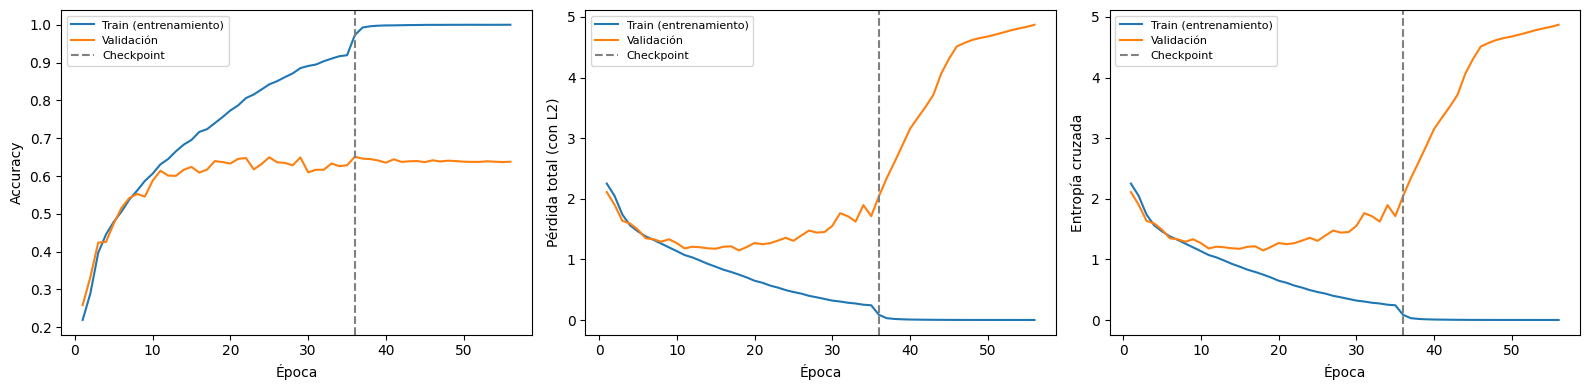

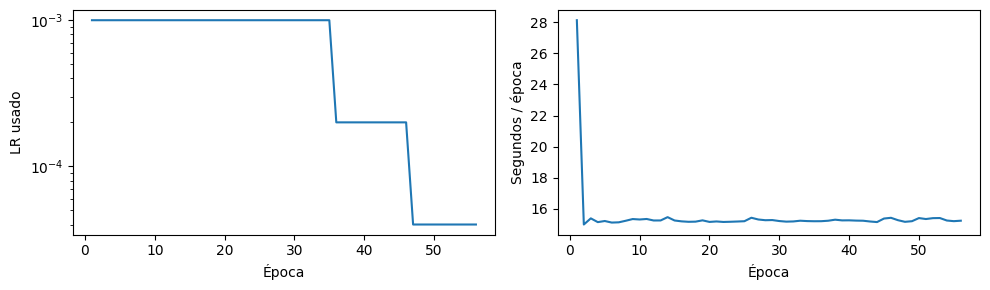

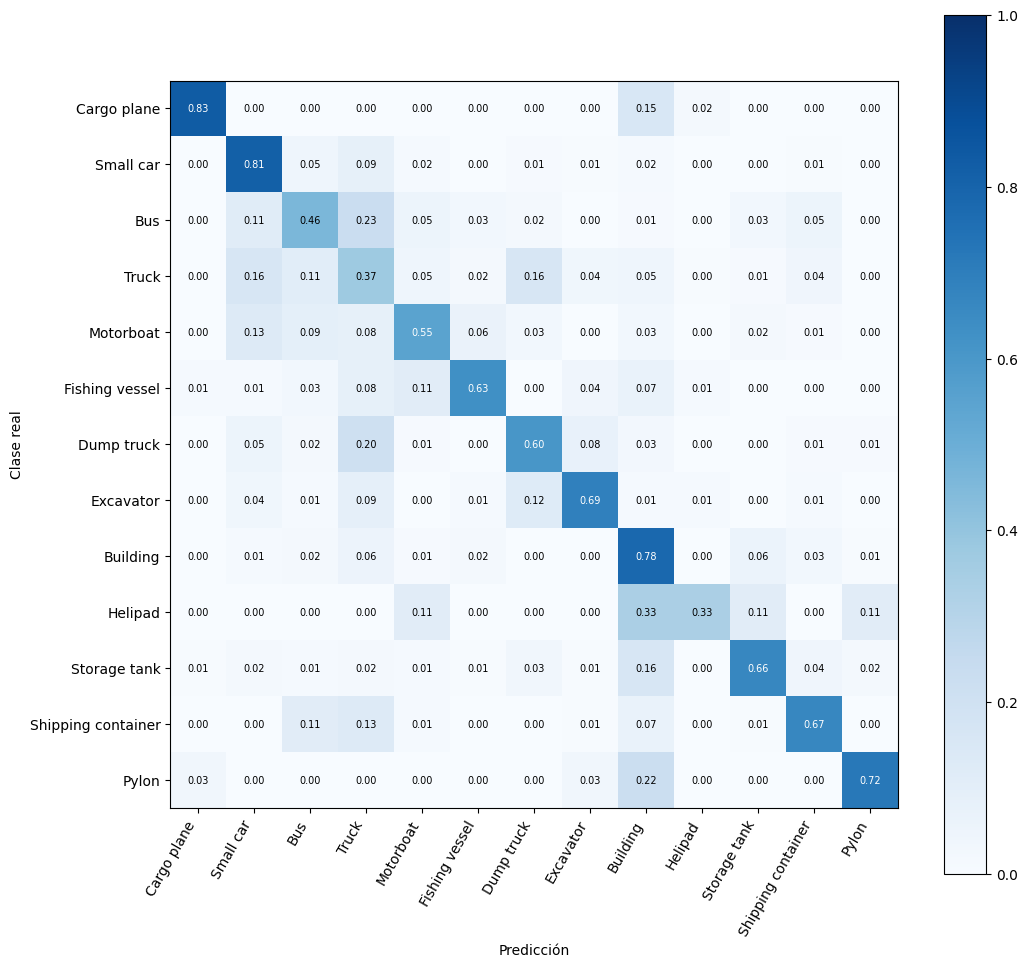

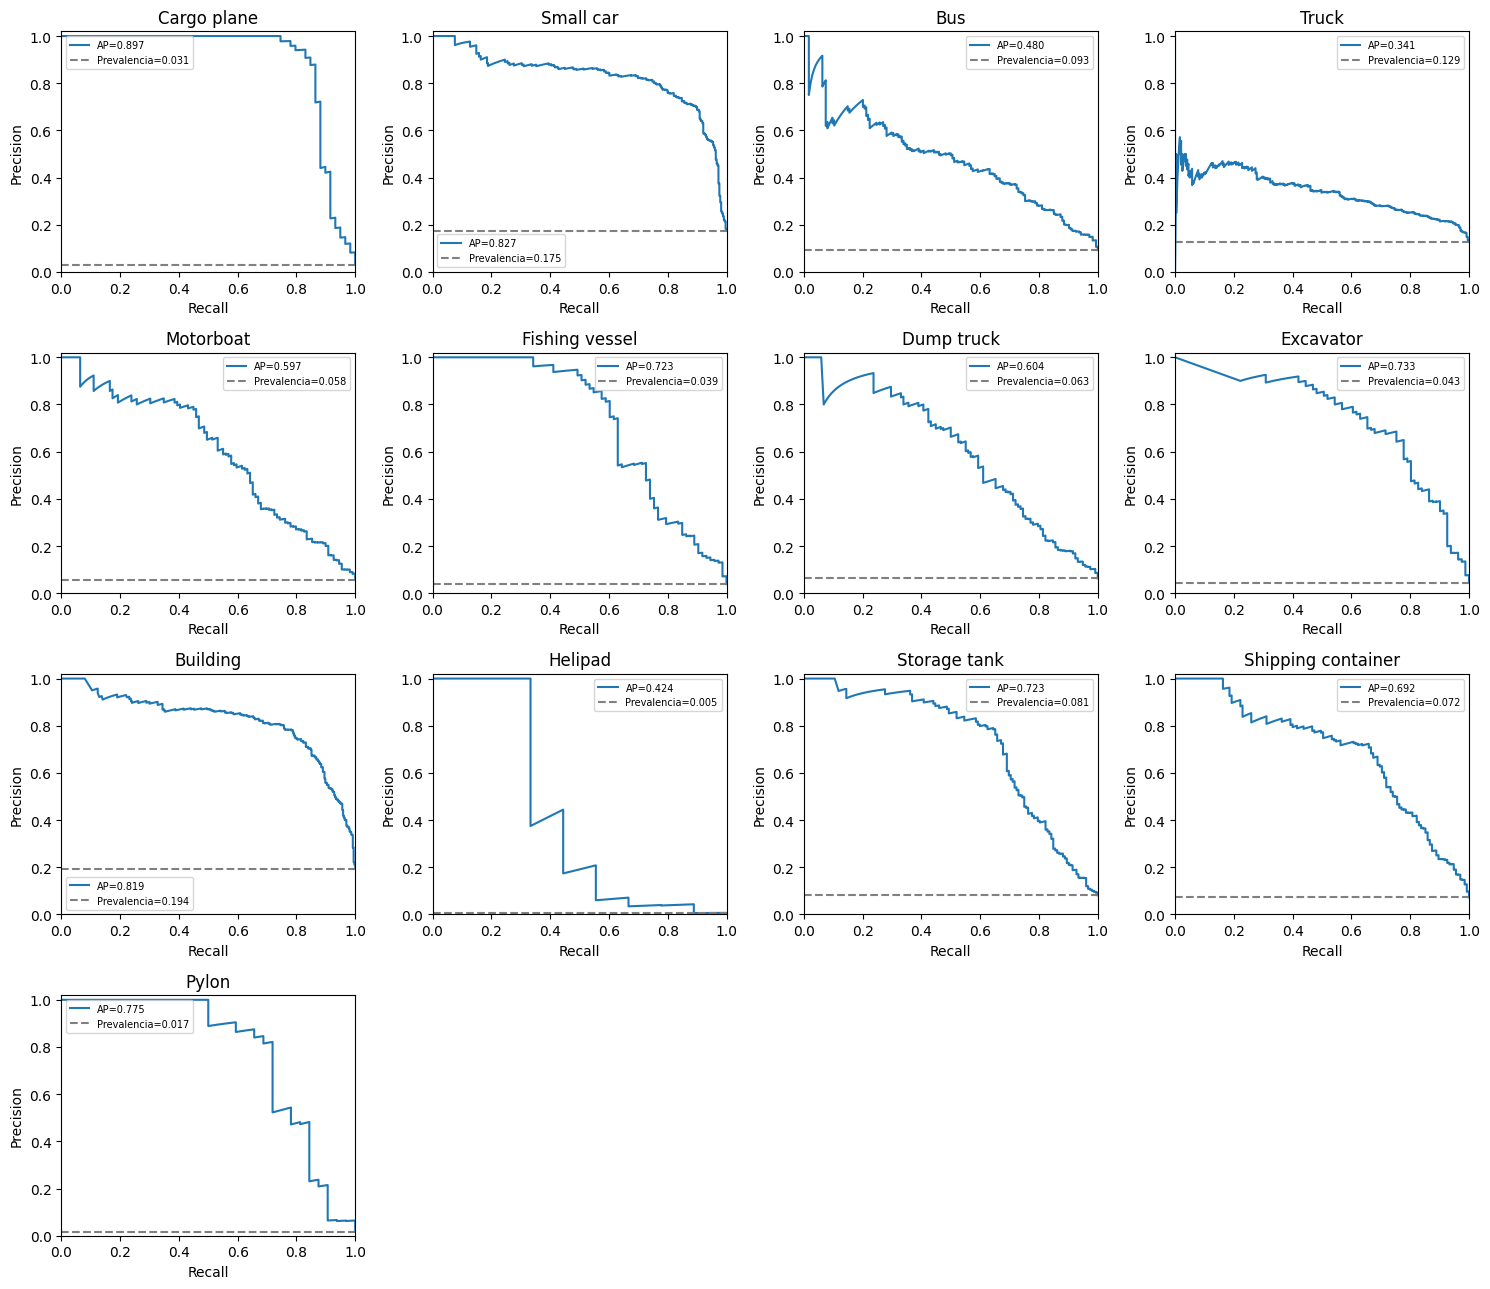

In [8]:
def plot_run(run_dir):
    cfg = read_json(artifact_path(run_dir, 'config.json'))
    h = read_json(artifact_path(run_dir, 'history.json'))
    m = read_json(artifact_path(run_dir, 'metrics.json'))
    classes = cfg['class_names']
    plots = run_dir / 'plots'
    epochs = np.arange(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, title in zip(axes, ['accuracy', 'loss', 'ce'], ['Accuracy', 'Pérdida total (con L2)', 'Entropía cruzada']):
        ax.plot(epochs, h[metric], label='Train (entrenamiento)')
        ax.plot(epochs, h['val_' + metric], label='Validación')
        ax.axvline(m['best_epoch'], color='grey', ls='--', label='Checkpoint')
        ax.set(xlabel='Época', ylabel=title)
        ax.legend(fontsize=8)
    save_figure(fig, plots, 'training_curves')
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].semilogy(epochs, h['lr_used'])
    axes[0].set(xlabel='Época', ylabel='LR usado')
    axes[1].plot(epochs, h['epoch_seconds'])
    axes[1].set(xlabel='Época', ylabel='Segundos / época')
    save_figure(fig, plots, 'learning_rate_time')
    with np.load(artifact_path(run_dir, 'validation_predictions.npz')) as saved:
        y, probs, cm = saved['y_true'], saved['probabilities'], saved['confusion_matrix']
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)
    ax.set(xticks=range(len(classes)), yticks=range(len(classes)), xticklabels=classes,
           yticklabels=classes, xlabel='Predicción', ylabel='Clase real')
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f'{norm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if norm[i, j] > 0.5 else 'black')
    save_figure(fig, plots, 'confusion_matrix')
    fig, axes = plt.subplots(4, 4, figsize=(15, 13))
    for i, (name, ax) in enumerate(zip(classes, axes.flat)):
        target = (y == i).astype(int)
        precision, recall, _ = precision_recall_curve(target, probs[:, i])
        ap = average_precision_score(target, probs[:, i])
        ax.plot(recall, precision, label=f'AP={ap:.3f}')
        ax.axhline(target.mean(), ls='--', color='grey', label=f'Prevalencia={target.mean():.3f}')
        ax.set(title=name, xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(fontsize=7)
    for ax in list(axes.flat)[len(classes):]:
        ax.set_visible(False)
    save_figure(fig, plots, 'precision_recall')

plot_run(RUN_DIR)

## 9. Comparar CNN propias y populares desde artefactos

Busca ejecuciones completas en cualquier carpeta bajo `CHALLENGE_DIR`, incluida la de la plantilla. Si hay muchas, rellenar
`SELECT_RUNS` con rutas relativas a `CHALLENGE_DIR`. Se exige el mismo dataset, reparto y orden de clases;
los cambios de resolución, entrenamiento o regularización aparecen en `comparison.csv` y deben explicarse.
Comparar preferentemente una variable por vez y presupuestos similares. La pérdida de comparación es **CE sin L2**.
Las curvas de train son métricas con regularización activa; la brecha usa la evaluación en inferencia.

Se dibujan curvas superpuestas, métricas agregadas, recall por clase y compromisos accuracy/parámetros/tiempo.
Para arquitecturas repetidas con varias semillas se informa media y desviación muestral; con una semilla no hay
estimación de dispersión. Son semillas de entrenamiento sobre una única partición, no validación cruzada.

Para comparar tras reiniciar el kernel, ejecuta únicamente la primera celda de código
(imports y utilidades), ajusta `SELECT_RUNS` y ejecuta esta celda. No hace falta
ejecutar las gráficas individuales, cargar las imágenes ni entrenar.

In [9]:
SELECT_RUNS = [
    'popular_architectures/round1/01_vgg16',
    'popular_architectures/round1/02_googlenet',
    'popular_architectures/round1/03_resnet18',
    'popular_architectures/round1/04_densenet121',
    'popular_architectures/round1/05_mobilenet_v2',
    'popular_architectures/round1/06_efficientnet_b0',
]

def load_runs(challenge_dir, selected=None):
    if selected:
        paths = [challenge_dir / p for p in selected]
    else:
        paths = set()
        for metrics_path in challenge_dir.rglob('metrics.json'):
            path = metrics_path.parent.parent if metrics_path.parent.name == 'artifacts' else metrics_path.parent
            if all(artifact_path(path, name).is_file() for name in ('config.json', 'history.json')):
                paths.add(path)
        paths = sorted(paths)
    runs = []
    for path in paths:
        cfg = read_json(artifact_path(path, 'config.json'))
        m = read_json(artifact_path(path, 'metrics.json'))
        h = read_json(artifact_path(path, 'history.json'))
        if m.get('schema_version') != 1:
            raise ValueError(f'Esquema de métricas incompatible: {path}')
        signature = (cfg['split_hash'], cfg['data_hash'], cfg['class_names'])
        if runs and signature != runs[0]['signature']:
            raise ValueError(f'Dataset/reparto/clases incompatibles: {path}')
        if cfg['weights'] is not None or not cfg['all_layers_trainable']:
            raise ValueError(f'No es un entrenamiento desde cero: {path}')
        label = path.relative_to(challenge_dir).as_posix()
        runs.append({'path': path, 'config': cfg, 'metrics': m, 'history': h,
                     'label': label, 'signature': signature})
    return runs

def compare_runs(runs, directory):
    if not runs:
        print('Aún no hay experimentos completos para comparar.')
        return
    directory.mkdir(parents=True, exist_ok=True)
    rows = []
    for run in runs:
        c, m = run['config'], run['metrics']
        rows.append({'run': run['label'], 'architecture': c['architecture'], 'seed': c['seed'],
                     'resolution': 'x'.join(map(str, c['image_size'])), 'batch': c['batch_size'],
                     'optimizer': c['optimizer'], 'initial_lr': c['learning_rate'],
                     'dropout': c['dropout'], 'l2': c['l2'], 'augmentation': c['augmentation'],
                     'monitor': c['monitor'], 'max_epochs': c['max_epochs'],
                     'best_epoch': m['best_epoch'], 'epochs_run': m['epochs_run'],
                     'accuracy': m['accuracy'], 'precision_macro': m['precision_macro'],
                     'recall_macro': m['recall_macro'], 'f1_macro': m['f1_macro'], 'ap_macro': m['ap_macro'],
                     'ce': m['valid_inference']['ce'], 'gap_pp': m['accuracy_gap_pp'],
                     'params': m['params'], 'fit_seconds': m['fit_seconds'],
                     'predict_ms_per_image': m['predict_ms_per_image'],
                     'environment': json.dumps(c['environment'], sort_keys=True)})
    with (directory / 'comparison.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
    for row in sorted(rows, key=lambda r: r['accuracy'], reverse=True):
        print(f"{row['run']}: acc={row['accuracy']:.3%}, F1={row['f1_macro']:.3%}, CE={row['ce']:.4f}")
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for run in runs:
        h = run['history']
        epochs = np.arange(1, len(h['loss']) + 1)
        line, = axes[0].plot(epochs, h['val_accuracy'], label=run['label'])
        axes[0].plot(epochs, h['accuracy'], ls=':', color=line.get_color(), alpha=0.5)
        axes[1].plot(epochs, h['val_ce'], label=run['label'])
        axes[2].plot(epochs, h['lr_used'], label=run['label'])
    for ax, title in zip(axes, ['Accuracy (validación sólida, train punteada)', 'CE validación sin L2', 'LR usado']):
        ax.set(xlabel='Época', ylabel=title)
        ax.legend(fontsize=6)
    axes[2].set_yscale('log')
    save_figure(fig, directory, 'comparison_curves')
    names = [r['label'] for r in runs]
    x = np.arange(len(runs))
    fig, ax = plt.subplots(figsize=(max(9, len(runs) * 1.5), 4))
    for offset, key in enumerate(['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']):
        ax.bar(x + (offset - 1.5) * 0.2, [r['metrics'][key] for r in runs], width=0.2, label=key)
    ax.set(xticks=x, xticklabels=names, ylim=(0, 1), ylabel='Validación')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=8)
    save_figure(fig, directory, 'comparison_metrics')
    matrix = np.array([[c['recall'] for c in r['metrics']['class_metrics']] for r in runs])
    fig, ax = plt.subplots(figsize=(13, max(3, len(runs) * 0.6)))
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(NUM_CLASSES), xticklabels=runs[0]['config']['class_names'],
           yticks=range(len(runs)), yticklabels=names, title='Recall por clase')
    plt.setp(ax.get_xticklabels(), rotation=50, ha='right')
    fig.colorbar(im, ax=ax)
    save_figure(fig, directory, 'comparison_class_recall')
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for run in runs:
        m = run['metrics']
        for ax, key in zip(axes, ['params', 'fit_seconds']):
            ax.scatter(m[key], m['accuracy'])
            ax.annotate(run['label'], (m[key], m['accuracy']), fontsize=7)
    for ax, title in zip(axes, ['Parámetros', 'Tiempo de fit (segundos)']):
        ax.set(xlabel=title, ylabel='Accuracy validación', xscale='log')
    save_figure(fig, directory, 'comparison_cost')
    # Agrupar solo configuraciones idénticas salvo semilla e identidad de ejecución.
    ignored = {'seed', 'experiment_id', 'hypothesis', 'initial_weights_sha256', 'environment',
               'data_load_seconds', 'cache_mode'}
    groups = {}
    for run in runs:
        key = digest_json({k: v for k, v in run['config'].items() if k not in ignored})
        groups.setdefault(key, []).append(run)
    summary = []
    for group in groups.values():
        seeds = [r['config']['seed'] for r in group]
        if len(seeds) != len(set(seeds)):
            raise ValueError('Semillas duplicadas para una misma configuración: revisa SELECT_RUNS.')
        entry = {'runs': [r['label'] for r in group], 'seeds': seeds, 'n': len(group)}
        for metric in ['accuracy', 'recall_macro', 'f1_macro']:
            values = [r['metrics'][metric] for r in group]
            entry[metric + '_mean'] = float(np.mean(values))
            entry[metric + '_std'] = float(np.std(values, ddof=1)) if len(group) > 1 else None
        summary.append(entry)
    write_json(directory / 'seed_summary.json', summary)

# runs = load_runs(CHALLENGE_DIR, SELECT_RUNS)
# compare_runs(runs, CHALLENGE_DIR / 'comparisons')

# Round 1: llamadas desactivadas para poder ejecutar todo el cuaderno.
# Al terminar las seis redes, descomenta ambas llamadas y ejecuta esta celda.


## 10. Ficha de resultados · completar tras cada experimento

- **Hipótesis y referencia:** [completar].
- **Único cambio o factores modificados:** [completar; arquitectura, tamaño, batch, regularización...].
- **Mejor época / ejecutadas; accuracy, recall, precision y F1 macro:** [consultar `artifacts/metrics.json`].
- **Brecha en inferencia y CE sin L2:** [completar].
- **Clases que mejoran/empeoran, incluido Helipad y su soporte:** [completar].
- **Coste:** [parámetros, tiempo, hardware y resolución].
- **Conclusión:** [qué apoya la evidencia; limitaciones de una semilla/partición].
- **Codabench, si se envió:** [fecha, identificador y métricas; mantener separado de validación].

Primeras comparaciones posibles: CNN pequeña frente a ffNN histórica (mismo reparto), profundidad/filtros,
resolución 32/64/128, Dropout, BN, L2 y aumentación por separado; después las arquitecturas de clase desde cero,
con resolución y protocolo compartidos. Si se cambia la cabeza de una arquitectura popular, indicarlo en la memoria.
Los resultados históricos no se mezclan automáticamente con los nuevos artefactos porque no comparten su esquema.